# Lab 13-08 · Transmission Lines: Sinusoidal Steady State

Companion to [chapter 13-08](../../chapters/13-08-transmission-lines-sinusoidal-steady-state.md). Four parts: standing-wave patterns for different loads; Γ and $Z_{in}$ as the line lengthens; quarter-wave transformer bandwidth; and how loss hides mismatch, with a distortionless line for contrast. Run the cells in order.

In [1]:
import cmath, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
Z0 = 50.0

def zin(ZL, Z0, bl):
    t = np.tan(bl)
    return Z0 * (ZL + 1j * Z0 * t) / (Z0 + 1j * ZL * t)

def gamma(Z, Z0=50.0):
    return (Z - Z0) / (Z + Z0)

## Part 1 · Standing waves

Plot $\lvert V(d)\rvert = \lvert 1 + \Gamma_Le^{-j2\beta d}\rvert$ (forward wave of 1 V) and the current $\lvert 1 - \Gamma_Le^{-j2\beta d}\rvert/Z_0$ over one wavelength from the load.

**Predict first:** for a 25 Ω load, is the voltage at the load a maximum or a minimum? For a load of 50 + j50 Ω, where is the first minimum?

50 + j50 ohm: Gamma = 0.4472 at 63.43 deg; first voltage minimum at 0.3381 wavelengths


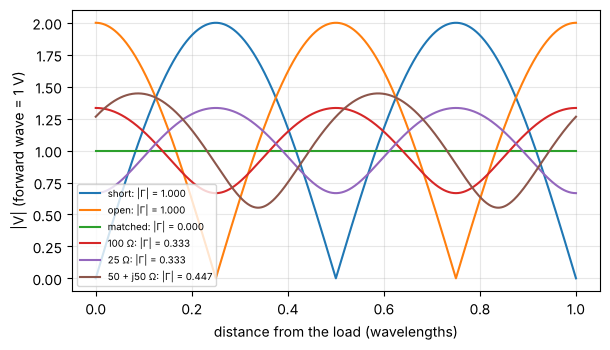

In [2]:
d = np.linspace(0, 1, 801)                     # distance from the load in wavelengths
loads = {'short': 0.0, 'open': 1e12, 'matched': 50.0, '100 Ω': 100.0, '25 Ω': 25.0, '50 + j50 Ω': 50 + 50j}
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for name, ZL in loads.items():
    G = gamma(ZL)
    ax.plot(d, np.abs(1 + G * np.exp(-4j * np.pi * d)), label=f"{name}: |Γ| = {abs(G):.3f}")
G = gamma(50 + 50j)
dmin = ((np.angle(G) + np.pi) / (4 * np.pi)) % 0.5
print(f"50 + j50 ohm: Gamma = {abs(G):.4f} at {np.degrees(np.angle(G)):.2f} deg; first voltage minimum at {dmin:.4f} wavelengths")
ax.set_xlabel('distance from the load (wavelengths)'); ax.set_ylabel('|V| (forward wave = 1 V)'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 2 · Γ circles, Z_in spirals

As the line between the load and the observer lengthens, $\Gamma(d) = \Gamma_Le^{-j2\beta d}$ circles the origin clockwise. Plot it for a lossless line and for a lossy one, and plot $Z_{in}$ in the complex plane.

**Predict first:** after what length does the picture repeat? What happens to the circle with loss?

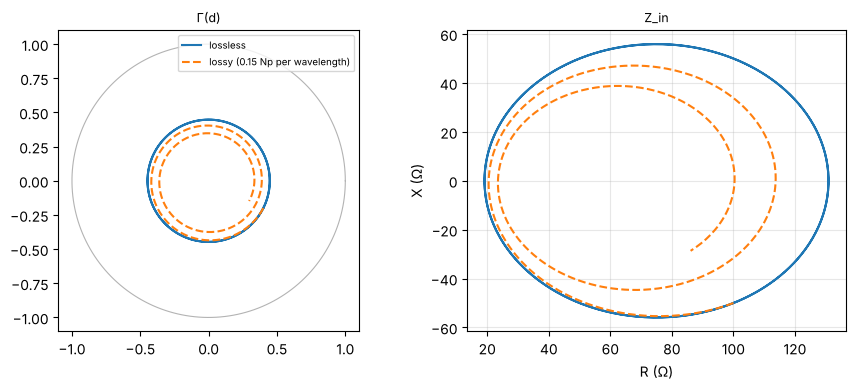

In [3]:
bl = np.linspace(0, 2 * np.pi, 721)            # beta*l up to one wavelength
ZL = 100 - 50j
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for alpha_l, style, label in ((0.0, '-', 'lossless'), (0.15, '--', 'lossy (0.15 Np per wavelength)')):
    G = gamma(ZL) * np.exp(-2j * bl - 2 * alpha_l * bl / (2 * np.pi))
    axes[0].plot(G.real, G.imag, style, label=label)
    Zi = Z0 * (1 + G) / (1 - G)
    axes[1].plot(Zi.real, Zi.imag, style, label=label)
th = np.linspace(0, 2 * np.pi, 200); axes[0].plot(np.cos(th), np.sin(th), color='0.7', lw=0.8)
axes[0].set_aspect('equal'); axes[0].set_title('Γ(d)', fontsize=9); axes[0].legend(fontsize=7)
axes[1].set_xlabel('R (Ω)'); axes[1].set_ylabel('X (Ω)'); axes[1].set_title('Z_in', fontsize=9); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 3 · Quarter-wave transformer bandwidth

For loads of 100, 200 and 500 Ω matched to 50 Ω by a single quarter-wave section, plot |Γ| against normalized frequency and find the bandwidth for |Γ| < 0.1.

**Predict first:** how much narrower is the 4:1 band than the 2:1 band?

100 ohm: Z1 = 70.71 ohm, bandwidth for |Gamma| < 0.1 = 36.70%
200 ohm: Z1 = 100.00 ohm, bandwidth for |Gamma| < 0.1 = 17.11%
500 ohm: Z1 = 158.11 ohm, bandwidth for |Gamma| < 0.1 = 9.00%


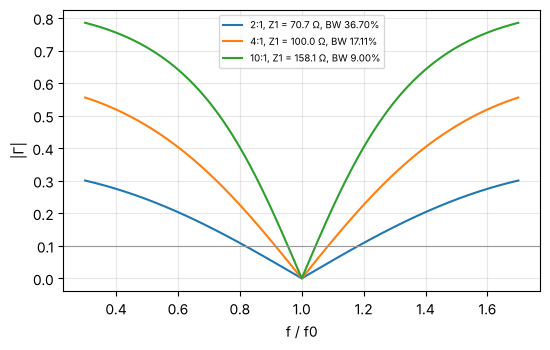

In [4]:
fn = np.linspace(0.3, 1.7, 1401)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for RL in (100, 200, 500):
    Z1 = math.sqrt(Z0 * RL)
    G = np.abs(gamma(zin(RL, Z1, np.pi / 2 * fn)))
    lo = brentq(lambda x: abs(gamma(zin(RL, Z1, np.pi / 2 * x))) - 0.1, 0.3, 1.0)
    hi = brentq(lambda x: abs(gamma(zin(RL, Z1, np.pi / 2 * x))) - 0.1, 1.0, 1.7)
    ax.plot(fn, G, label=f"{RL / Z0:.0f}:1, Z1 = {Z1:.1f} Ω, BW {100 * (hi - lo):.2f}%")
    print(f"{RL} ohm: Z1 = {Z1:.2f} ohm, bandwidth for |Gamma| < 0.1 = {100 * (hi - lo):.2f}%")
ax.axhline(0.1, color='0.6', lw=0.8); ax.set_xlabel('f / f0'); ax.set_ylabel('|Γ|'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · Loss hides mismatch; the distortionless line

First, the apparent return loss of a short circuit seen through RG-58 at 1 GHz (0.7054 dB/m) against cable length. Then send a Gaussian pulse down two lines with the same $R'$, $L'$, $C'$: one with $G'$ = 0 and one with the Heaviside $G'$, and compare the received shapes.

**Predict first:** what return loss does a short show through 5 m of the cable?

short through 5 m: apparent return loss 7.054 dB


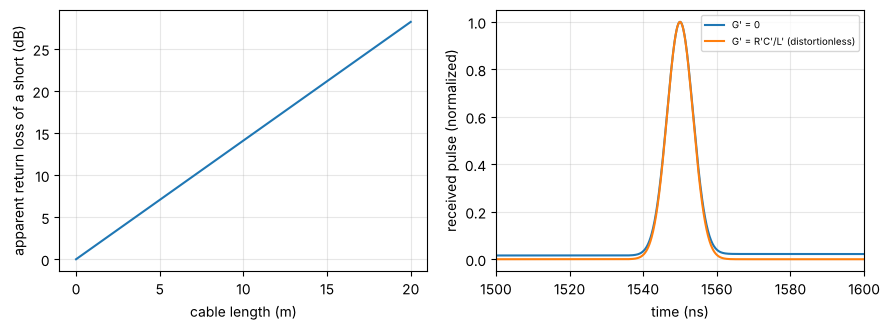

In [5]:
lengths = np.linspace(0, 20, 201)
RL_app = 2 * 0.7054 * lengths
print(f"short through 5 m: apparent return loss {2 * 0.7054 * 5:.3f} dB")
R, L, C = 0.5, 250e-9, 100e-12
f = np.fft.rfftfreq(2**14, d=1e-10)
w = 2 * np.pi * f
t = np.arange(2**14) * 1e-10
pulse = np.exp(-((t - 50e-9) / 5e-9) ** 2)
P = np.fft.rfft(pulse)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(lengths, RL_app); axes[0].set_xlabel('cable length (m)'); axes[0].set_ylabel('apparent return loss of a short (dB)'); axes[0].grid(alpha=0.3)
for G, label in ((0.0, "G' = 0"), (R * C / L, "G' = R'C'/L' (distortionless)")):
    gam = np.sqrt((R + 1j * w * L) * (G + 1j * w * C)); gam[0] = math.sqrt(R * G)
    out = np.fft.irfft(P * np.exp(-gam * 300.0), n=len(t))
    axes[1].plot(t * 1e9, out / out.max(), label=label)
axes[1].set_xlim(1500, 1600); axes[1].set_xlabel('time (ns)'); axes[1].set_ylabel('received pulse (normalized)'); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## What to notice

- Voltage maxima sit where Γ(d) is real and positive, minima where it is negative; voltage and current swap roles every quarter wavelength.
- Γ(d) repeats every half wavelength on a lossless line and spirals inward with loss: the Smith chart (13-09) is this picture with impedance grid lines drawn on it.
- A single quarter-wave section gives about 37% bandwidth for a 2:1 step and about 17% for 4:1 at |Γ| < 0.1.
- Five metres of RG-58 make a short circuit look like a 7 dB return loss; the distortionless line delivers a smaller but undistorted pulse.